<a href="https://colab.research.google.com/github/mrayhanz/PCVK-Ganjil-2026/blob/main/week5_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Identitas Diri**

Nama : Muhammad Rayhan Zamzami

Kelas : TI-3G

Absen : 19

NAMA : Muhammad Rayhan Zamzami
NIM : 244107020027 | N = 27
bins   : 64
clip   : 2.0
tile   : 5
L      : 2
WAKTU : 2026-09-28 20:21:23 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 2ccb2fc8170d78fb


Text(0.5, 1.0, '244107020027 - CLAHE clip 2.0')

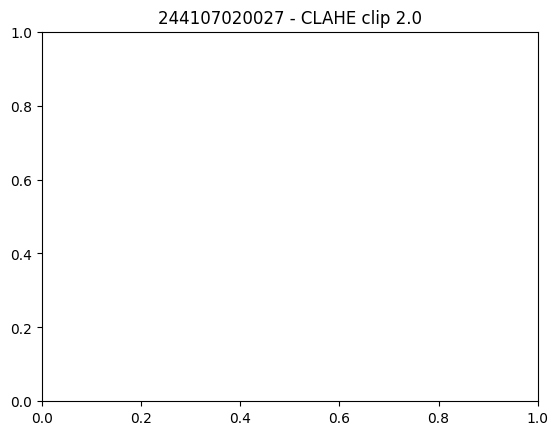

In [5]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
import matplotlib.pyplot as plt
NAMA = 'Muhammad Rayhan Zamzami'
NIM = '244107020027' # ganti dengan NIM Anda
N = int(NIM[-3:])
PARAM = {
'bins' : 2 ** ((N % 4) + 3),
'clip' : round(1.0 + (N % 5) * 0.5, 1),
'tile' : (N % 4) + 2,
'L' : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)
for k, v in PARAM.items():
  print('%-6s :' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])
plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']))

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

In [13]:
CONTOH = '/content/drive/MyDrive/PCVK-2025/'
BASE = '/content/drive/MyDrive/PCVK-2025/'

# E-1 PERCOBAAN HISTOGRAM

=== Perbandingan histogram: lena.jpg ===
Kanal red | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0
Kanal green | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0
Kanal blue | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0


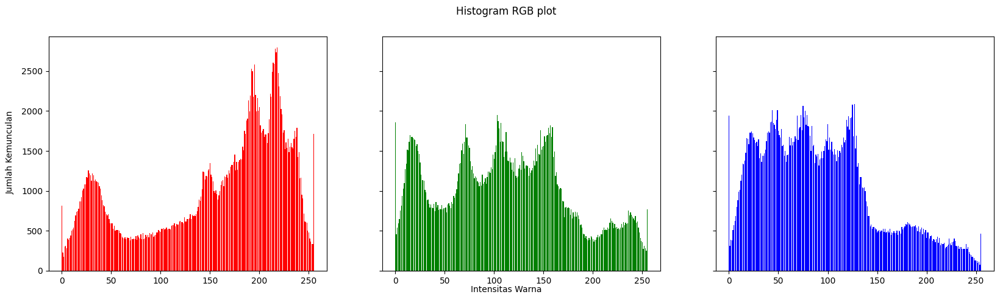

In [9]:
# E-1 dan pertanyaan praktikum 1

img = cv.imread(os.path.join(CONTOH, 'lena.jpg'))
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

names = np.arange(256)

manual_red = [0] * 256
manual_green = [0] * 256
manual_blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        manual_red[img[y, x, 0]] += 1
        manual_green[img[y, x, 1]] += 1
        manual_blue[img[y, x, 2]] += 1

names = np.arange(256)

fig, axs = plt.subplots(
    1, 3,
    figsize=(20, 5),
    sharex=True,
    sharey=True
)

fig.suptitle('Histogram RGB plot')

fig.text(
    0.09,
    0.5,
    'Jumlah Kemunculan',
    va='center',
    rotation='vertical'
)

fig.text(
    0.5,
    0.04,
    'Intensitas Warna',
    ha='center'
)

axs[0].bar(names, manual_red, color='red')
axs[1].bar(names, manual_green, color='green')
axs[2].bar(names, manual_blue, color='blue')


# Histogram citra dengan numpy.histogram lena

np_red, _ = np.histogram(
    img[:, :, 0],
    bins=256,
    range=(0, 256)
)

np_green, _ = np.histogram(
    img[:, :, 1],
    bins=256,
    range=(0, 256)
)

np_blue, _ = np.histogram(
    img[:, :, 2],
    bins=256,
    range=(0, 256)
)


# Histogram citra dengan cv.calcHist

cv_red = cv.calcHist(
    [img], [0], None, [256], [0, 256]
).flatten().astype(int)

cv_green = cv.calcHist(
    [img], [1], None, [256], [0, 256]
).flatten().astype(int)

cv_blue = cv.calcHist(
    [img], [2], None, [256], [0, 256]
).flatten().astype(int)


# Perbandingan selisih maksimum

print("=== Perbandingan histogram: lena.jpg ===")

diff_r_manual_np = np.max(np.abs(manual_red - np_red))
diff_r_manual_cv = np.max(np.abs(manual_red - cv_red))
diff_r_np_cv = np.max(np.abs(np_red - cv_red))

print(
    f"Kanal red | manual vs numpy: {diff_r_manual_np} | "
    f"manual vs cv: {diff_r_manual_cv} | "
    f"numpy vs cv: {diff_r_np_cv}"
)

diff_g_manual_np = np.max(np.abs(manual_green - np_green))
diff_g_manual_cv = np.max(np.abs(manual_green - cv_green))
diff_g_np_cv = np.max(np.abs(np_green - cv_green))

print(
    f"Kanal green | manual vs numpy: {diff_g_manual_np} | "
    f"manual vs cv: {diff_g_manual_cv} | "
    f"numpy vs cv: {diff_g_np_cv}"
)

diff_b_manual_np = np.max(np.abs(manual_blue - np_blue))
diff_b_manual_cv = np.max(np.abs(manual_blue - cv_blue))
diff_b_np_cv = np.max(np.abs(np_blue - cv_blue))

print(
    f"Kanal blue | manual vs numpy: {diff_b_manual_np} | "
    f"manual vs cv: {diff_b_manual_cv} | "
    f"numpy vs cv: {diff_b_np_cv}"
)


=== Perbandingan histogram: ktm1a.jpg ===
Kanal red | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0
Kanal green | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0
Kanal blue | manual vs numpy: 0 | manual vs cv: 0 | numpy vs cv: 0


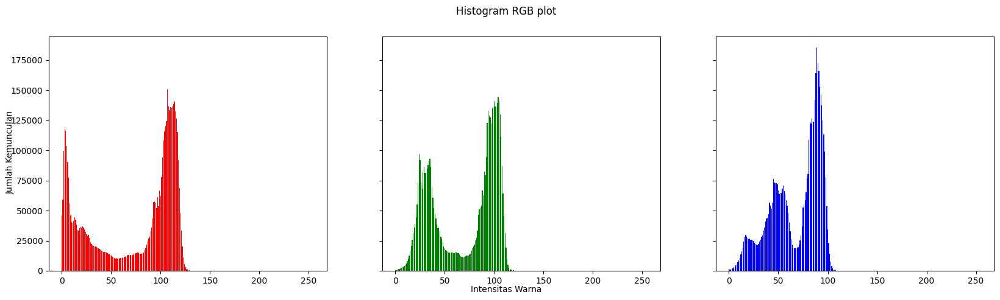

In [10]:
# Pertanyaan praktikum 1 untuk ktm1a

img = cv.imread(os.path.join(BASE + 'KTM1a.jpeg'))
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

names = np.arange(256)
red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red[img[y, x, 0]] += 1
        green[img[y, x, 1]] += 1
        blue[img[y, x, 2]] += 1

names = np.arange(256)
manual_red = np.array(red)
manual_green = np.array(green)
manual_blue = np.array(blue)

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va = 'center', rotation = 'vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha = 'center')
axs[0].bar(names, red, color = 'red')
axs[1].bar(names, green, color = 'green')
axs[2].bar(names, blue, color = 'blue')

# Histogram citra dengan numpy.histogram ktm1a
np_red, _ = np.histogram(img[:, :, 0], bins=256, range=(0, 256))
np_green, _ = np.histogram(img[:, :, 1], bins=256, range=(0, 256))
np_blue, _ = np.histogram(img[:, :, 2], bins=256, range=(0, 256))

# Histogram citra dengan cv.calchist
cv_red = cv.calcHist([img], [0], None, [256], [0, 256]).flatten().astype(int)
cv_green = cv.calcHist([img], [1], None, [256], [0, 256]).flatten().astype(int)
cv_blue = cv.calcHist([img], [2], None, [256], [0, 256]).flatten().astype(int)

# Perbandingan selisih maksimum
print("=== Perbandingan histogram: ktm1a.jpg ===")

diff_r_manual_np = np.max(np.abs(manual_red - np_red))
diff_r_manual_cv = np.max(np.abs(manual_red - cv_red))
diff_r_np_cv = np.max(np.abs(np_red - cv_red))
print(f"Kanal red | manual vs numpy: {diff_r_manual_np} | manual vs cv: {diff_r_manual_cv} | numpy vs cv: {diff_r_np_cv}")

diff_g_manual_np = np.max(np.abs(manual_green - np_green))
diff_g_manual_cv = np.max(np.abs(manual_green - cv_green))
diff_g_np_cv = np.max(np.abs(np_green - cv_green))
print(f"Kanal green | manual vs numpy: {diff_g_manual_np} | manual vs cv: {diff_g_manual_cv} | numpy vs cv: {diff_g_np_cv}")

diff_b_manual_np = np.max(np.abs(manual_blue - np_blue))
diff_b_manual_cv = np.max(np.abs(manual_blue - cv_blue))
diff_b_np_cv = np.max(np.abs(np_blue - cv_blue))
print(f"Kanal blue | manual vs numpy: {diff_b_manual_np} | manual vs cv: {diff_b_manual_cv} | numpy vs cv: {diff_b_np_cv}")

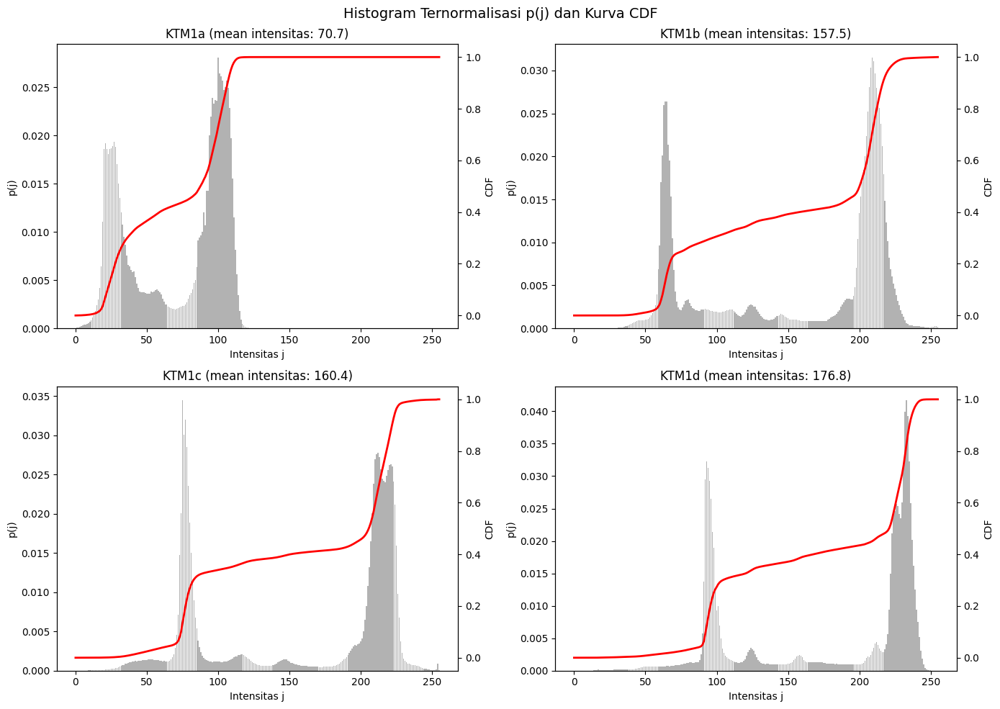

In [16]:
# E-1 Pertanyaan Praktikum 2

paths = {
    'KTM1a': os.path.join(BASE, 'KTM1a.jpeg'),
    'KTM1b': os.path.join(BASE, 'KTM1b.jpeg'),
    'KTM1c': os.path.join(BASE, 'KTM1c.jpeg'),
    'KTM1d': os.path.join(BASE, 'KTM1d.jpeg'),
}

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.ravel()

for ax, (label, path) in zip(axs, paths.items()):
    img = cv.imread(path)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    histogram = np.zeros(256, dtype=int)

    for value in gray.ravel():
        histogram[value] += 1

    p = histogram / histogram.sum()
    cdf = np.cumsum(p)

    ax.bar(np.arange(256), p, color='gray', alpha=0.6, label='p(j)')

    ax_cdf = ax.twinx()
    ax_cdf.plot(np.arange(256), cdf, color='red', linewidth=2, label='CDF')

    ax.set_title(f'{label} (mean intensitas: {gray.mean():.1f})')
    ax.set_xlabel('Intensitas j')
    ax.set_ylabel('p(j)')
    ax_cdf.set_ylabel('CDF')

fig.suptitle('Histogram Ternormalisasi p(j) dan Kurva CDF', fontsize=14)
plt.tight_layout()
plt.show()

# KAITAN DENGAN KONDISI PENCAHAYAAN

Perbedaan pencahayaan dapat dilihat dari posisi penyebaran nilai intensitas pada
masing-masing gambar. Pada KTM1a, nilai piksel cenderung berada pada rentang
intensitas rendah sehingga bagian gelap lebih mendominasi gambar. Akibatnya,
CDF lebih cepat mencapai nilai mendekati 1 karena sebagian besar piksel sudah
terkumpul pada intensitas yang rendah. Dari kondisi tersebut dapat diperkirakan
bahwa pencahayaan saat mengambil KTM1a relatif kurang.

Sedangkan pada KTM1c, penyebaran nilai piksel bergeser ke intensitas yang lebih
tinggi. Hal ini membuat kenaikan CDF tidak terlalu besar pada bagian awal dan
baru meningkat lebih jelas ketika memasuki intensitas sekitar 150–200. Dengan
kata lain, lebih banyak piksel pada KTM1c memiliki tingkat kecerahan yang tinggi.
Kondisi ini sesuai dengan penggunaan sumber cahaya yang lebih kuat dan flash,
sehingga hasil gambar terlihat lebih terang dibandingkan KTM1a.

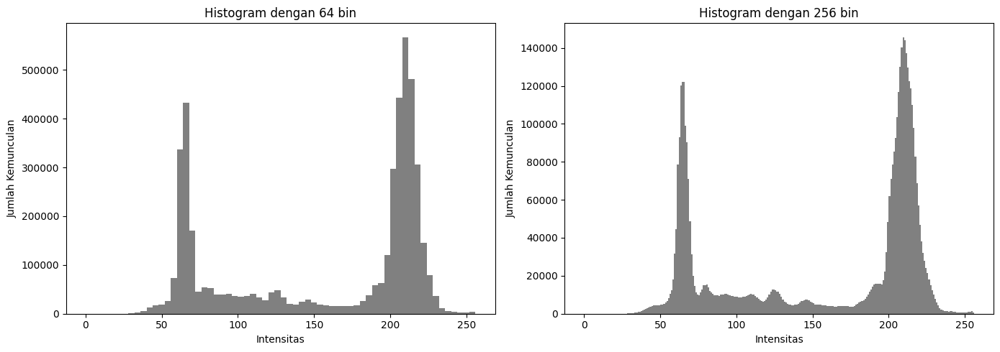

In [17]:
# E-1 Pertanyaan Praktikum 3

img = cv.imread(os.path.join(BASE, 'KTM1b.jpeg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Histogram dengan parameter bins
axs[0].hist(gray.ravel(), bins=PARAM['bins'], range=(0, 256), color='gray')
axs[0].set_title(f"Histogram dengan {PARAM['bins']} bin")
axs[0].set_xlabel('Intensitas')
axs[0].set_ylabel('Jumlah Kemunculan')

# Histogram dengan 256 bin
axs[1].hist(gray.ravel(), bins=256, range=(0, 256), color='gray')
axs[1].set_title('Histogram dengan 256 bin')
axs[1].set_xlabel('Intensitas')
axs[1].set_ylabel('Jumlah Kemunculan')

plt.tight_layout()
plt.show()

## INFORMASI YANG HILANG

1. Histogram dengan 256 bin mampu memperlihatkan perubahan frekuensi pada setiap
nilai intensitas secara lebih detail. Ketika jumlah bin dikurangi menjadi 32,
beberapa intensitas yang sebenarnya berbeda akan masuk ke kelompok yang sama.

2. Detail kecil pada histogram juga menjadi kurang terlihat. Puncak yang sebelumnya
terlihat jelas pada histogram 256 bin dapat berubah menjadi lebih lebar ketika
menggunakan 32 bin karena beberapa nilai piksel digabungkan.

3. Perbedaan antarintensitas yang letaknya berdekatan pada sumbu x menjadi sulit
diamati. Misalnya, intensitas 198, 199, dan 200 dapat memiliki frekuensi yang
berbeda pada histogram 256 bin, tetapi perbedaannya tidak dapat diketahui dengan
jelas ketika menggunakan jumlah bin yang lebih sedikit.

4. Posisi puncak histogram juga menjadi kurang spesifik. Histogram 256 bin dapat
menunjukkan intensitas tempat puncak terjadi secara lebih tepat, sedangkan
histogram 32 bin hanya memberikan informasi mengenai rentang intensitasnya.

# E-2 HISTOGRAM EQUALIZATION

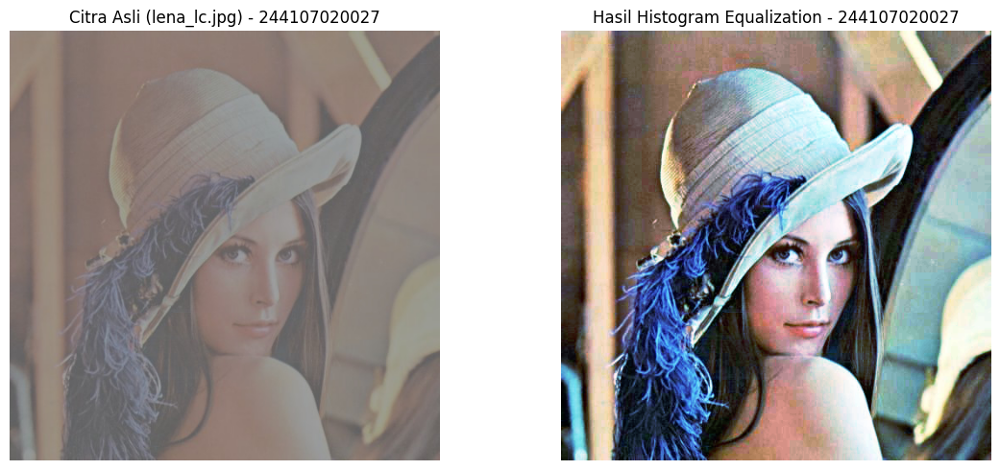

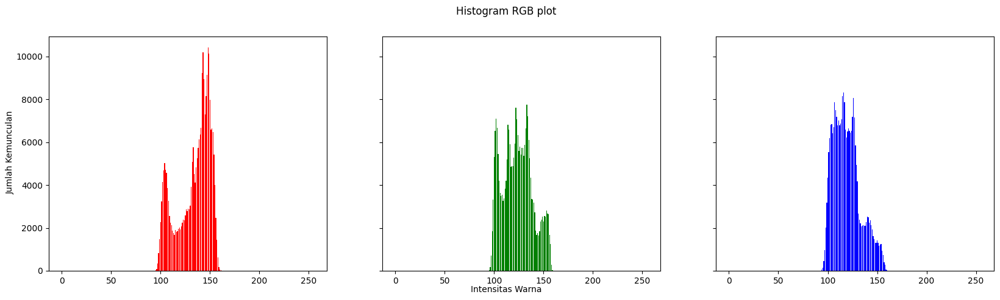

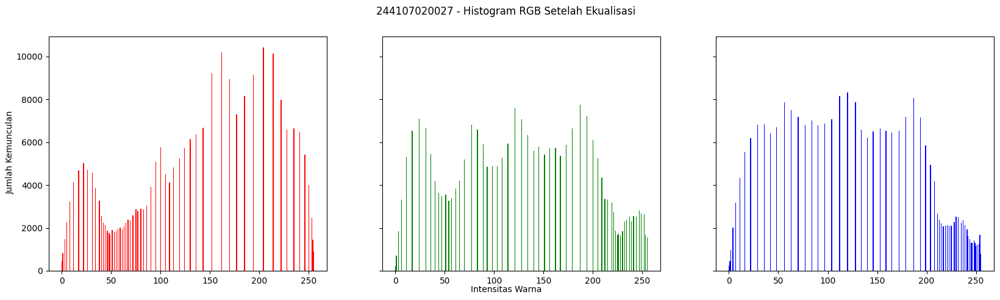

In [11]:
# E2 Percobaan 1

img_lena = cv.imread(CONTOH + 'lena_lc.jpg')
img_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_lena)

names = np.arange(256)
red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red[img_lena[y, x, 0]] += 1
        green[img_lena[y, x, 1]] += 1
        blue[img_lena[y, x, 2]] += 1

total_pixels = height * width

# Variabel untuk menampung nilai cdf
red_cdf = 0
green_cdf = 0
blue_cdf = 0

# Array untuk menyimpan peta perubahan warna (pemetaan nilai pixel lama ke baru)
map_red = [0] * 256
map_green = [0] * 256
map_blue = [0] * 256

for i in range(256):
    red_cdf += red[i]
    green_cdf += green[i]
    blue_cdf += blue[i]

    map_red[i] = round((red_cdf / total_pixels) * 255)
    map_green[i] = round((green_cdf / total_pixels) * 255)
    map_blue[i] = round((blue_cdf / total_pixels) * 255)

img_eq_lena = np.zeros_like(img_lena)

for y in range(0, height):
    for x in range(0, width):
        # Mengganti pixel lama dengan pixel baru berdasarkan pemetaan
        img_eq_lena[y, x, 0] = map_red[img_lena[y, x, 0]]
        img_eq_lena[y, x, 1] = map_green[img_lena[y, x, 1]]
        img_eq_lena[y, x, 2] = map_blue[img_lena[y, x, 2]]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(img_lena)
axs[0].set_title('Citra Asli (lena_lc.jpg) - ' + NIM)
axs[0].axis('off')

axs[1].imshow(img_eq_lena)
axs[1].set_title('Hasil Histogram Equalization - ' + NIM)
axs[1].axis('off')

plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va = 'center', rotation = 'vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha = 'center')
axs[0].bar(names, red, color = 'red')
axs[1].bar(names, green, color = 'green')
axs[2].bar(names, blue, color = 'blue')

# Hitung histogram dari CITRA HASIL EKUALISASI (img_eq_lena), bukan dari manual
red_eq = [0] * 256
green_eq = [0] * 256
blue_eq = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red_eq[img_eq_lena[y, x, 0]] += 1
        green_eq[img_eq_lena[y, x, 1]] += 1
        blue_eq[img_eq_lena[y, x, 2]] += 1

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle(NIM + ' - Histogram RGB Setelah Ekualisasi')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red_eq, color='red')
axs[1].bar(names, green_eq, color='green')
axs[2].bar(names, blue_eq, color='blue')

plt.show()

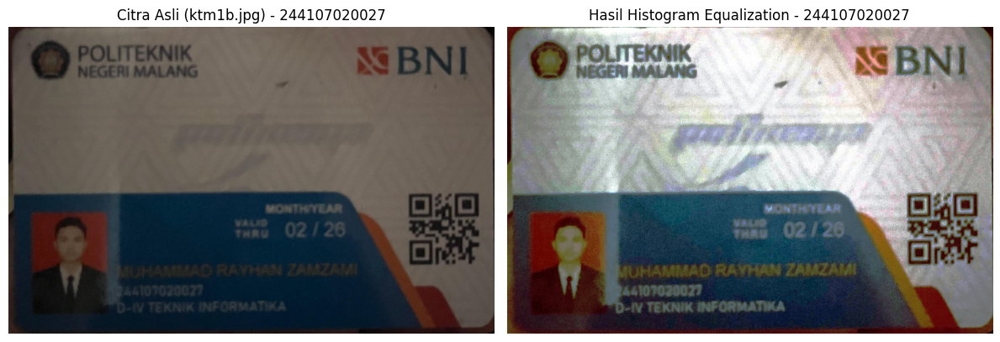

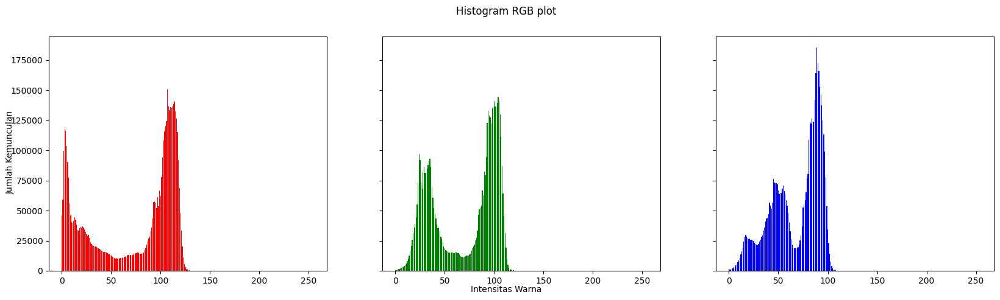

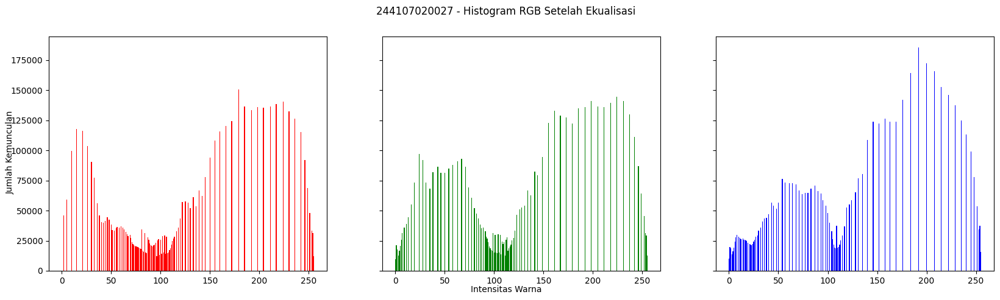

In [12]:
#E2 Percobaan 1 bagian ktm

img_ktm = cv.imread(os.path.join(BASE, 'KTM1a.jpeg'))
img_ktm = cv.cvtColor(img_ktm, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_ktm)

names = np.arange(256)
red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red[img_ktm[y, x, 0]] += 1
        green[img_ktm[y, x, 1]] += 1
        blue[img_ktm[y, x, 2]] += 1

total_pixels = height * width

# Variabel untuk menampung nilai cdf
red_cdf = 0
green_cdf = 0
blue_cdf = 0

# Array untuk menyimpan peta perubahan warna (pemetaan nilai pixel lama ke baru)
map_red = [0] * 256
map_green = [0] * 256
map_blue = [0] * 256

for i in range(256):
    red_cdf += red[i]
    green_cdf += green[i]
    blue_cdf += blue[i]

    map_red[i] = round((red_cdf / total_pixels) * 255)
    map_green[i] = round((green_cdf / total_pixels) * 255)
    map_blue[i] = round((blue_cdf / total_pixels) * 255)

img_eq_ktm = np.zeros_like(img_ktm)

for y in range(0, height):
    for x in range(0, width):
        # Mengganti pixel lama dengan pixel baru berdasarkan pemetaan
        img_eq_ktm[y, x, 0] = map_red[img_ktm[y, x, 0]]
        img_eq_ktm[y, x, 1] = map_green[img_ktm[y, x, 1]]
        img_eq_ktm[y, x, 2] = map_blue[img_ktm[y, x, 2]]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(img_ktm)
axs[0].set_title('Citra Asli (ktm1b.jpg) - ' + NIM)
axs[0].axis('off')

axs[1].imshow(img_eq_ktm)
axs[1].set_title('Hasil Histogram Equalization - ' + NIM)
axs[1].axis('off')

plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va = 'center', rotation = 'vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha = 'center')
axs[0].bar(names, red, color = 'red')
axs[1].bar(names, green, color = 'green')
axs[2].bar(names, blue, color = 'blue')

red_eq = [0] * 256
green_eq = [0] * 256
blue_eq = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red_eq[img_eq_ktm[y, x, 0]] += 1
        green_eq[img_eq_ktm[y, x, 1]] += 1
        blue_eq[img_eq_ktm[y, x, 2]] += 1

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle(NIM + ' - Histogram RGB Setelah Ekualisasi')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red_eq, color='red')
axs[1].bar(names, green_eq, color='green')
axs[2].bar(names, blue_eq, color='blue')

plt.show()

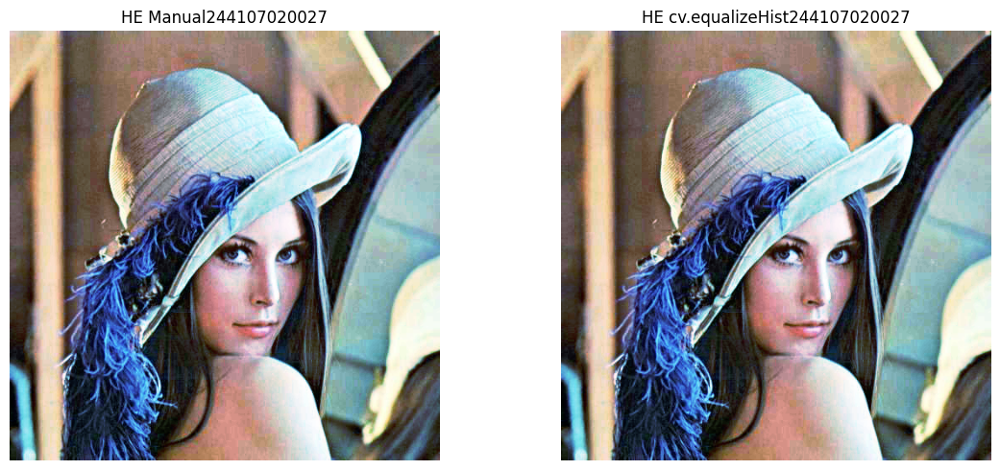

Selisih maksimum (lena_lc.jpg) manual vs cv.equalizeHist: 0


In [18]:
# E-2 Percobaan 2

r, g, b = cv.split(img_lena)
r_equalized = cv.equalizeHist(r)
g_equalized = cv.equalizeHist(g)
b_equalized = cv.equalizeHist(b)
img_eq_cv = cv.merge([r_equalized, g_equalized, b_equalized])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(img_eq_lena)
axs[0].set_title('HE Manual' + NIM)
axs[0].axis('off')
axs[1].imshow(img_eq_cv)
axs[1].set_title('HE cv.equalizeHist' + NIM)
axs[1].axis('off')
plt.tight_layout()
plt.show()

diff_lena = np.max(np.abs(img_eq_lena.astype(int) - img_eq_cv.astype(int)))
print("Selisih maksimum (lena_lc.jpg) manual vs cv.equalizeHist:", diff_lena)

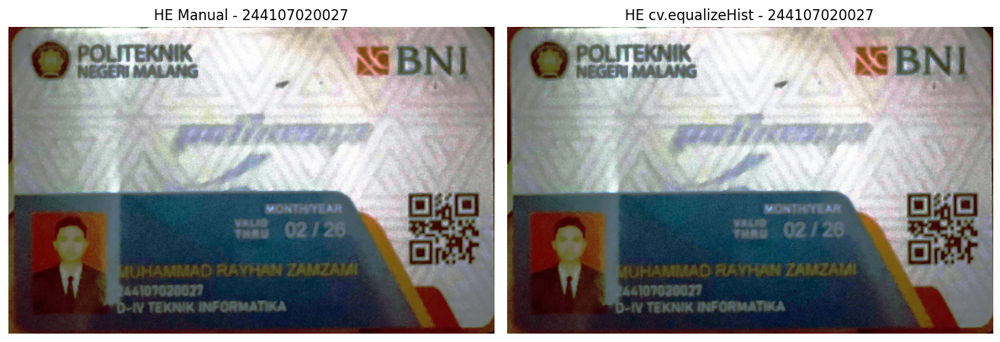

Selisih maksimum (KTM1a.jpeg) manual vs cv.equalizeHist: 2


In [19]:
# E-2 Percobaan 2 bagian ktm

r, g, b = cv.split(img_ktm)
r_equalized = cv.equalizeHist(r)
g_equalized = cv.equalizeHist(g)
b_equalized = cv.equalizeHist(b)
img_eq_cv = cv.merge([r_equalized, g_equalized, b_equalized])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(img_eq_ktm)
axs[0].set_title('HE Manual - ' + NIM)
axs[0].axis('off')
axs[1].imshow(img_eq_cv)
axs[1].set_title('HE cv.equalizeHist - ' + NIM)
axs[1].axis('off')
plt.tight_layout()
plt.show()

diff_ktm = np.max(np.abs(img_eq_ktm.astype(int) - img_eq_cv.astype(int)))
print("Selisih maksimum (KTM1a.jpeg) manual vs cv.equalizeHist:", diff_ktm)

Percobaan ini membandingkan hasil Histogram Equalization manual dengan fungsi cv.equalizeHist(). Pada citra lena_lc, hasil keduanya sama dengan selisih maksimum 0. Sedangkan pada citra KTM terdapat selisih kecil sebesar 2, yang disebabkan oleh perbedaan proses normalisasi CDF pada metode manual dan cv.equalizeHist().

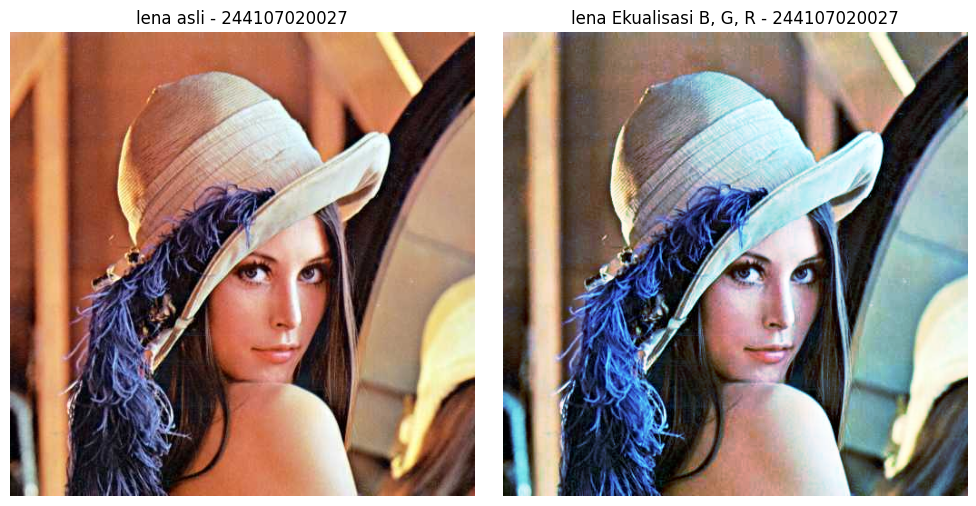

In [20]:
# E-2 Percobaan 3

berkas = CONTOH + 'lena.jpg'
bgr = cv.imread(berkas)
kanal = list(cv.split(bgr))

for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])

he_rgb = cv.merge(kanal)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
axs[0].set_title('lena asli - ' + NIM)
axs[0].axis('off')
axs[1].imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
axs[1].set_title('lena Ekualisasi B, G, R - ' + NIM)
axs[1].axis('off')
plt.tight_layout()
plt.show()

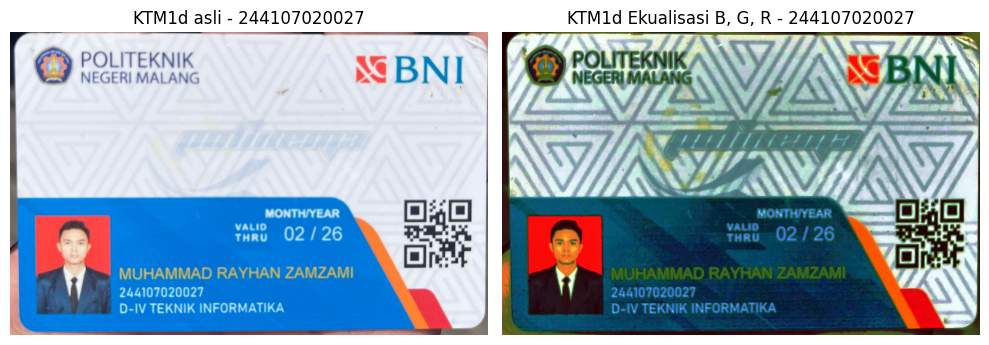

In [21]:
# E-2 Percobaan 3 bagian ktm

berkas2 = os.path.join(BASE, 'KTM1d.jpeg')
bgr2 = cv.imread(berkas2)
kanal2 = list(cv.split(bgr2))

for i in range(3):
    kanal2[i] = cv.equalizeHist(kanal2[i])

he_rgb2 = cv.merge(kanal2)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(cv.cvtColor(bgr2, cv.COLOR_BGR2RGB))
axs[0].set_title('KTM1d asli - ' + NIM)
axs[0].axis('off')
axs[1].imshow(cv.cvtColor(he_rgb2, cv.COLOR_BGR2RGB))
axs[1].set_title('KTM1d Ekualisasi B, G, R - ' + NIM)
axs[1].axis('off')
plt.tight_layout()
plt.show()

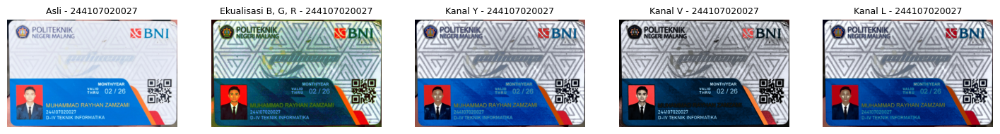

In [22]:
# E-2 Percobaan 4

ycrcb = cv.cvtColor(bgr2, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)

he_y = cv.cvtColor(
    cv.merge([cv.equalizeHist(y), cr, cb]),
    cv.COLOR_YCrCb2BGR
)

# varian setara pada ruang warna lain
hsv = cv.cvtColor(bgr2, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)

he_v = cv.cvtColor(
    cv.merge([h, sat, cv.equalizeHist(v)]),
    cv.COLOR_HSV2BGR
)

lab = cv.cvtColor(bgr2, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)

he_l = cv.cvtColor(
    cv.merge([cv.equalizeHist(l), a, b]),
    cv.COLOR_LAB2BGR
)

judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
citra = [bgr2, he_rgb2, he_y, he_v, he_l]

plt.figure(figsize=(18, 4))

for i, (c, t) in enumerate(zip(citra, judul), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(t + ' - ' + NIM, fontsize=9)
    plt.axis('off')

plt.show()

In [23]:
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)
    return d.mean()

print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))

for t, c in zip(judul, citra):
    print(
        '%-22s %16.2f %16.1f'
        % (
            t,
            geser_hue(bgr2, c) * 2,
            cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
        )
    )

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            176.8
Ekualisasi B, G, R                40.31            124.1
Kanal Y                            2.88            133.7
Kanal V                            2.52            110.7
Kanal L                            5.33            123.7


# Tabel Hasil Percobaan 4

| Cara ekualisasi | Rata-rata pergeseran Hue (°) | Rerata kecerahan sesudah | Catatan pengamatan visual |
|---|---:|---:|---|
| Citra asli | 0.00 | 176.8 | Citra asli |
| Ekualisasi kanal B, G, R | 40.31 | 124.1 | Warna mengalami perubahan cukup terlihat |
| Kanal Y (YCrCb) | 2.88 | 133.7 | Warna relatif tetap, kontras meningkat |
| Kanal V (HSV) | 2.52 | 110.7 | Citra menjadi lebih gelap |
| Kanal L (LAB) | 5.33 | 123.7 | Kontras meningkat dengan sedikit perubahan warna |
| Kanal Y CLAHE | 0.21 | 133.2 | Kontras lebih terkontrol dan warna relatif tetap |

## JAWABAN PERTANYAAN
1. Ekualisasi kanal B, G, dan R menghasilkan perubahan Hue paling besar, yaitu 40.31°. Nilai tersebut jauh lebih tinggi dibandingkan metode yang hanya melakukan ekualisasi pada kanal kecerahan. Hal ini terjadi karena ketiga kanal warna diproses secara terpisah sehingga perbandingan nilai antar kanal dapat berubah dan menyebabkan warna citra ikut bergeser.

2. Pergeseran Hue pada kanal Y, V, dan L tidak benar-benar menjadi nol karena setelah proses ekualisasi, citra perlu dikonversi kembali ke format BGR. Dalam proses tersebut terdapat pembulatan nilai dan pembatasan nilai piksel pada rentang 0–255. Perubahan kecil ini dapat memengaruhi komposisi warna sehingga Hue mengalami sedikit pergeseran.

3. Berdasarkan hasil pengukuran, kanal Y dapat digunakan untuk foto KTM karena menghasilkan pergeseran Hue yang relatif kecil, yaitu 2.88°, dengan rerata kecerahan 133.7. Selain itu, bagian tulisan pada KTM juga tetap dapat terlihat dengan cukup jelas setelah proses ekualisasi. Hasil ini menunjukkan bahwa perubahan kontras dapat dilakukan tanpa mengubah warna citra secara besar.

4. Penggunaan CLAHE pada kanal Y menghasilkan pergeseran Hue sebesar 0.21° dengan rerata kecerahan 133.2. Nilai pergeseran Hue tersebut lebih kecil dibandingkan equalizeHist() pada kanal Y yang menghasilkan 2.88°. Hal ini menunjukkan bahwa CLAHE memberikan perubahan yang lebih terkontrol pada citra karena proses peningkatan kontras dilakukan secara lokal menggunakan beberapa area (tile), bukan langsung pada keseluruhan histogram.

## PERTANYAAN PRAKTIKUM 2

In [25]:
# Pertanyaan Praktikum E2 - 1

img_a = cv.imread(os.path.join(BASE, 'KTM1a.jpeg'))
gray_a = cv.cvtColor(img_a, cv.COLOR_BGR2GRAY)

height_a, width_a = np.shape(gray_a)

# Histogram manual
hist_a = [0] * 256

for y in range(0, height_a):
    for x in range(0, width_a):
        hist_a[gray_a[y, x]] += 1

total_pixels_a = height_a * width_a

cdf_a = 0
map_a = [0] * 256

for i in range(256):
    cdf_a += hist_a[i]
    map_a[i] = round((cdf_a / total_pixels_a) * 255)

hasil_manual_a = np.zeros_like(gray_a)

for y in range(0, height_a):
    for x in range(0, width_a):
        hasil_manual_a[y, x] = map_a[gray_a[y, x]]

hasil_cv_a = cv.equalizeHist(gray_a)

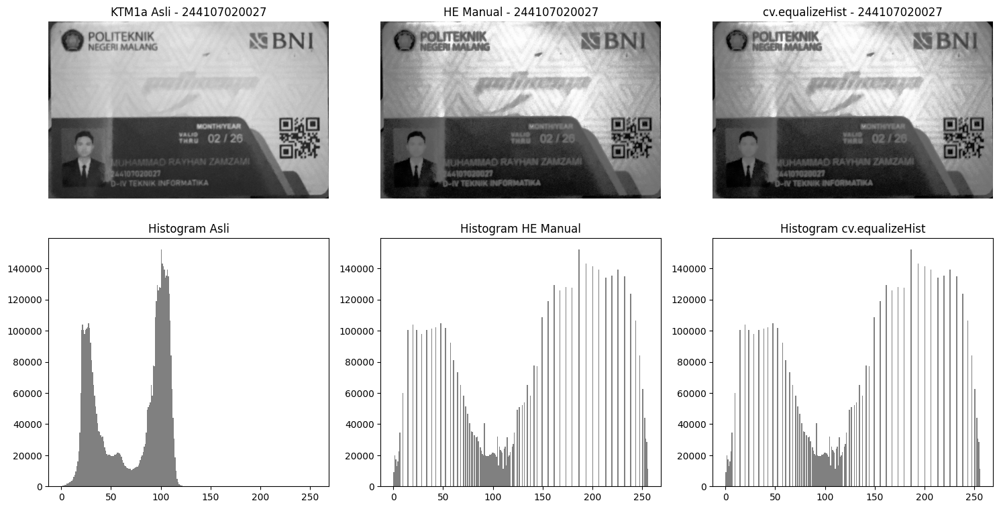

In [26]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))

axs[0,0].imshow(gray_a, cmap='gray')
axs[0,0].set_title('KTM1a Asli - ' + NIM)
axs[0,0].axis('off')

axs[0,1].imshow(hasil_manual_a, cmap='gray')
axs[0,1].set_title('HE Manual - ' + NIM)
axs[0,1].axis('off')

axs[0,2].imshow(hasil_cv_a, cmap='gray')
axs[0,2].set_title('cv.equalizeHist - ' + NIM)
axs[0,2].axis('off')

axs[1,0].hist(gray_a.ravel(), bins=256, range=(0,256), color='gray')
axs[1,0].set_title('Histogram Asli')

axs[1,1].hist(hasil_manual_a.ravel(), bins=256, range=(0,256), color='gray')
axs[1,1].set_title('Histogram HE Manual')

axs[1,2].hist(hasil_cv_a.ravel(), bins=256, range=(0,256), color='gray')
axs[1,2].set_title('Histogram cv.equalizeHist')

plt.tight_layout()
plt.show()

In [27]:
mse_manual = np.mean(
    (gray_a.astype(np.float64) - hasil_manual_a.astype(np.float64)) ** 2
)

mse_cv = np.mean(
    (gray_a.astype(np.float64) - hasil_cv_a.astype(np.float64)) ** 2
)

psnr_manual = 10 * np.log10((255 ** 2) / mse_manual)
psnr_cv = 10 * np.log10((255 ** 2) / mse_cv)

print("PSNR HE Manual:", psnr_manual, "dB")
print("PSNR cv.equalizeHist:", psnr_cv, "dB")

PSNR HE Manual: 10.924246762666975 dB
PSNR cv.equalizeHist: 10.924246762666975 dB


Nilai PSNR setelah ekualisasi menjadi lebih rendah karena proses histogram
equalization memang mengubah nilai piksel pada citra asli. Perubahan tersebut
membuat perbedaan antara citra sebelum dan sesudah ekualisasi menjadi lebih besar,
sehingga nilai PSNR menurun.

Walaupun nilai PSNR turun, hasil ekualisasi dapat terlihat lebih jelas karena
kontras citra meningkat dan detail pada bagian yang sebelumnya sulit terlihat
menjadi lebih mudah dibedakan. Oleh karena itu, PSNR kurang tepat jika digunakan
sebagai satu-satunya ukuran untuk menilai keterbacaan sebuah citra. PSNR lebih
menggambarkan tingkat kemiripan nilai piksel, bukan seberapa mudah informasi
pada citra dapat dibaca.

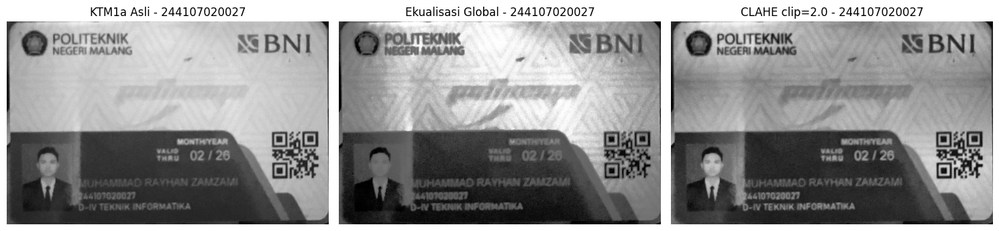

In [12]:
# Pertanyaan Praktikum E2 - 2a

img_clahe = cv.imread(os.path.join(BASE, 'KTM1a.jpeg'))
gray_clahe = cv.cvtColor(img_clahe, cv.COLOR_BGR2GRAY)

clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(PARAM['tile'], PARAM['tile'])
)

hasil_clahe = clahe.apply(gray_clahe)

hasil_global = cv.equalizeHist(gray_clahe)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(gray_clahe, cmap='gray')
axs[0].set_title('KTM1a Asli - ' + NIM)
axs[0].axis('off')

axs[1].imshow(hasil_global, cmap='gray')
axs[1].set_title('Ekualisasi Global - ' + NIM)
axs[1].axis('off')

axs[2].imshow(hasil_clahe, cmap='gray')
axs[2].set_title(
    f'CLAHE clip={PARAM["clip"]} - ' + NIM
)
axs[2].axis('off')

plt.tight_layout()
plt.show()

Pada hasil CLAHE, bagian nama dan NIM pada kartu terlihat lebih terbaca
dibandingkan hasil ekualisasi global. Detail pada area lokal menjadi lebih
terlihat karena peningkatan kontras dilakukan pada bagian-bagian kecil citra,
sehingga detail yang sebelumnya kurang jelas dapat lebih mudah dibedakan.

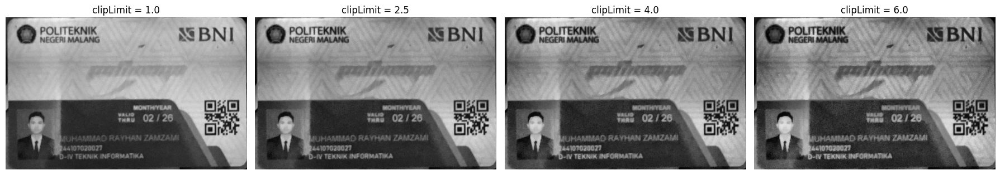

In [23]:
# Pertanyaan Praktikum E2 - 2b

clip_values = [1.0, 2.5, 4.0, 6.0]

fig, axs = plt.subplots(1, 4, figsize=(18, 5))

for ax, clip in zip(axs, clip_values):
    clahe_test = cv.createCLAHE(
        clipLimit=clip,
        tileGridSize=(PARAM['tile'], PARAM['tile'])
    )

    hasil_test = clahe_test.apply(gray_clahe)

    ax.imshow(hasil_test, cmap='gray')
    ax.set_title(f'clipLimit = {clip}')
    ax.axis('off')

plt.tight_layout()
plt.show()

Dari beberapa nilai yang diuji, clipLimit 4.0 memberikan hasil yang paling
sesuai karena tulisan nama dan NIM terlihat lebih jelas tanpa membuat detail
gambar menjadi terlalu kasar. Ketika clipLimit dinaikkan menjadi 6.0, beberapa
bagian background mulai menunjukkan noise dan tekstur yang lebih menonjol.
Hal tersebut menunjukkan bahwa peningkatan clipLimit yang terlalu tinggi dapat
membuat detail kecil dan noise ikut diperkuat.

# E-3 TUGAS PRAKTIKUM DITHERING

In [28]:
def floyd_steinberg(channel, L):
    img = channel.astype(np.float32).copy()

    height, width = img.shape
    step = 255.0 / (L - 1)

    for y in range(height):
        for x in range(width):
            old_pixel = img[y, x]

            new_pixel = np.round(old_pixel / step) * step

            img[y, x] = new_pixel
            error = old_pixel - new_pixel

            if x + 1 < width:
                img[y, x + 1] += error * 7 / 16

            if y + 1 < height and x > 0:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < height:
                img[y + 1, x] += error * 5 / 16

            if y + 1 < height and x + 1 < width:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(img, 0, 255).astype(np.uint8)

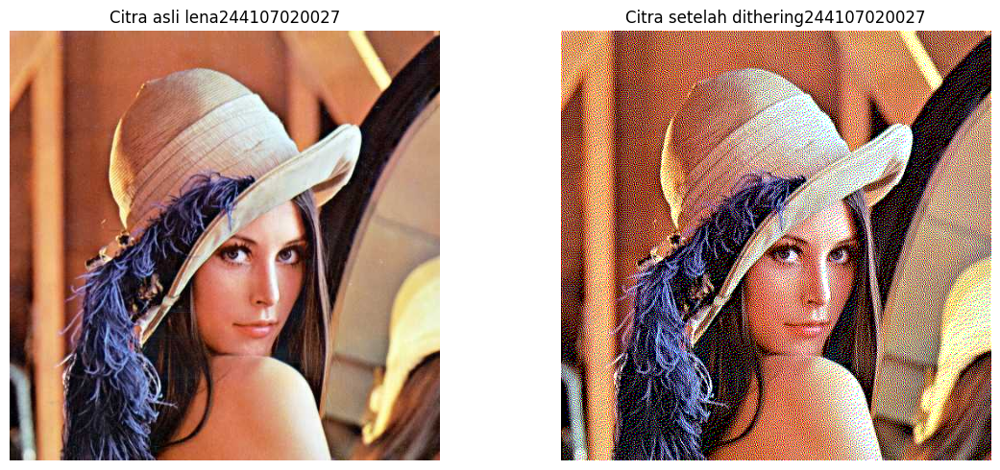

In [21]:
img_lena = cv.imread(os.path.join(CONTOH, 'lena.jpg'))
img_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

hasil_lena = floyd_steinberg(img_lena, PARAM['L'])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].imshow(img_lena)
axs[0].set_title('Citra asli lena' + NIM)
axs[0].axis('off')

axs[1].imshow(hasil_lena)
axs[1].set_title('Citra setelah dithering' + NIM)
axs[1].axis('off')

plt.tight_layout()
plt.show()

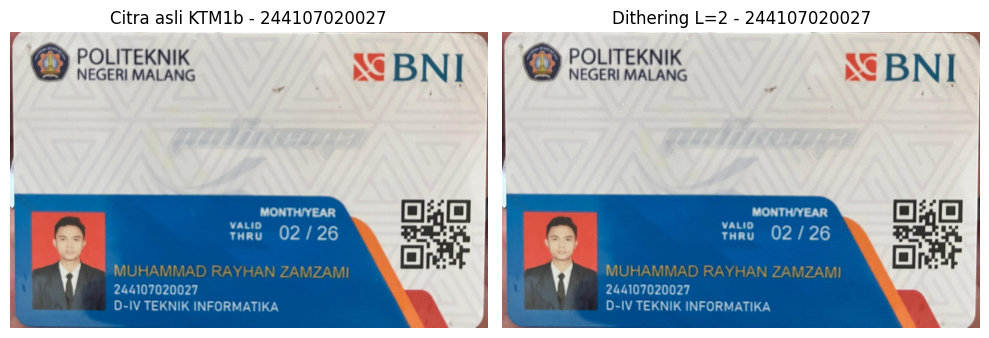

Rata-rata selisih piksel: 82.08706164725731
Selisih maksimum piksel: 254


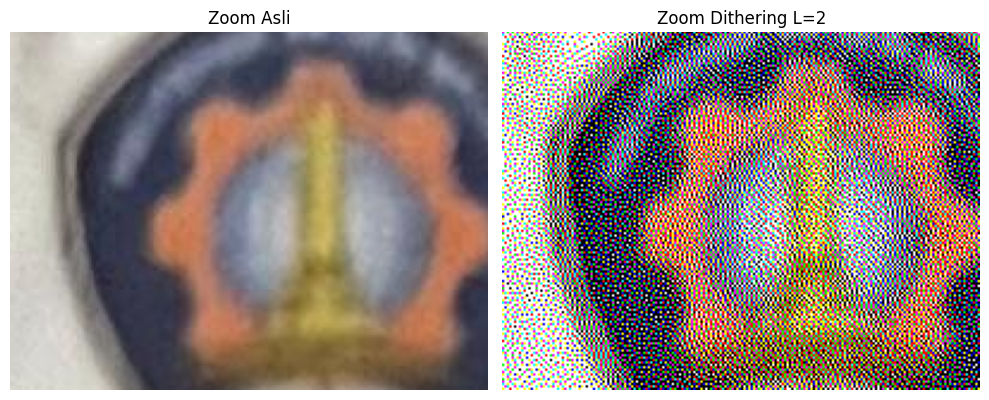

In [30]:
img_ktm_b = cv.imread(os.path.join(BASE, 'KTM1b.jpeg'))
b, g, r = cv.split(img_ktm_b)

b_dither = floyd_steinberg(b, L=PARAM['L'])
g_dither = floyd_steinberg(g, L=PARAM['L'])
r_dither = floyd_steinberg(r, L=PARAM['L'])

hasil_dither_ktm_b = cv.merge([b_dither, g_dither, r_dither])

# Menampilkan citra asli dan hasil dithering

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(cv.cvtColor(img_ktm_b, cv.COLOR_BGR2RGB))
axs[0].set_title('Citra asli KTM1b - ' + NIM)
axs[0].axis('off')

axs[1].imshow(cv.cvtColor(hasil_dither_ktm_b, cv.COLOR_BGR2RGB))
axs[1].set_title(f'Dithering L={PARAM["L"]} - ' + NIM)
axs[1].axis('off')

plt.tight_layout()
plt.show()


# Perbandingan selisih piksel

diff_ktm_b = np.abs(
    img_ktm_b.astype(int) -
    hasil_dither_ktm_b.astype(int)
)

print("Rata-rata selisih piksel:", diff_ktm_b.mean())
print("Selisih maksimum piksel:", diff_ktm_b.max())


# Zoom citra asli dan hasil dithering

y1, y2, x1, x2 = 100, 250, 100, 300

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(
    cv.cvtColor(
        img_ktm_b[y1:y2, x1:x2],
        cv.COLOR_BGR2RGB
    )
)
axs[0].set_title('Zoom Asli')
axs[0].axis('off')

axs[1].imshow(
    cv.cvtColor(
        hasil_dither_ktm_b[y1:y2, x1:x2],
        cv.COLOR_BGR2RGB
    )
)
axs[1].set_title(f'Zoom Dithering L={PARAM["L"]}')
axs[1].axis('off')

plt.tight_layout()
plt.show()

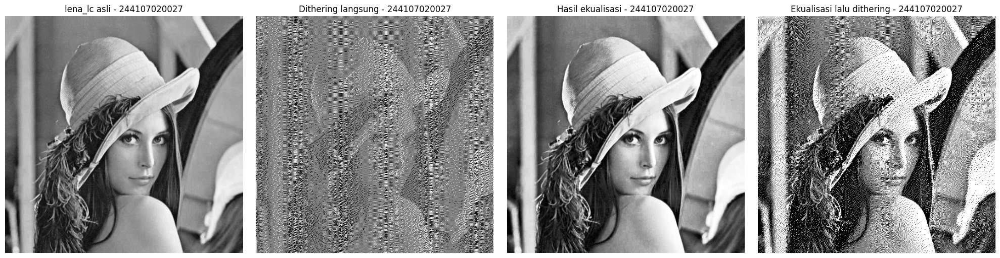

In [31]:
# E-3 Tugas Praktikum 2
# lena_lc.jpg

img_lc = cv.imread(os.path.join(CONTOH, 'lena_lc.jpg'))
gray_lc = cv.cvtColor(img_lc, cv.COLOR_BGR2GRAY)

dither_langsung_lc = floyd_steinberg(gray_lc, L=2)

hasil_eq_lc = cv.equalizeHist(gray_lc)
dither_eq_lc = floyd_steinberg(hasil_eq_lc, L=2)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))

axs[0].imshow(gray_lc, cmap='gray')
axs[0].set_title('lena_lc asli - ' + NIM)
axs[0].axis('off')

axs[1].imshow(dither_langsung_lc, cmap='gray')
axs[1].set_title('Dithering langsung - ' + NIM)
axs[1].axis('off')

axs[2].imshow(hasil_eq_lc, cmap='gray')
axs[2].set_title('Hasil ekualisasi - ' + NIM)
axs[2].axis('off')

axs[3].imshow(dither_eq_lc, cmap='gray')
axs[3].set_title('Ekualisasi lalu dithering - ' + NIM)
axs[3].axis('off')

plt.tight_layout()
plt.show()

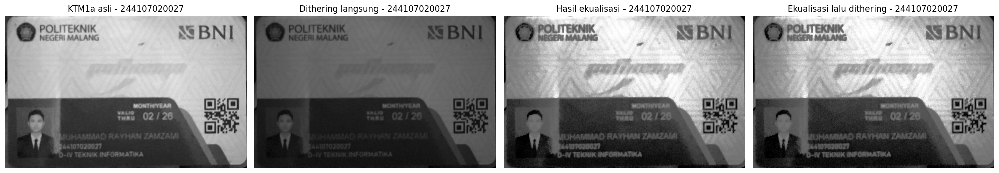

Nilai unik di 'Hasil ekualisasi': [ 0  1  2  3  4  5  6  9 14 19] ... total: 95
Nilai unik di 'Ekualisasi lalu dithering': [  0 255]


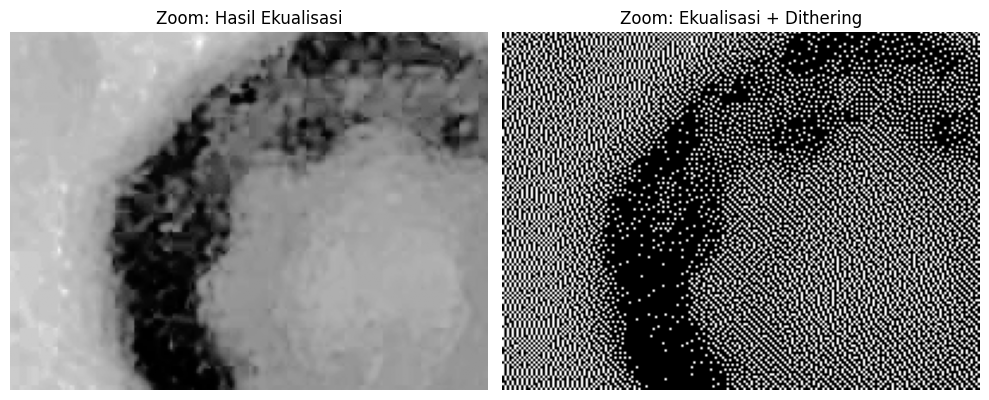

In [33]:
# KTM1a.jpg

img_a = cv.imread(os.path.join(BASE, 'KTM1a.jpeg'))
gray_a = cv.cvtColor(img_a, cv.COLOR_BGR2GRAY)

dither_langsung_a = floyd_steinberg(gray_a, L=2)

hasil_eq_a = cv.equalizeHist(gray_a)
dither_eq_a = floyd_steinberg(hasil_eq_a, L=2)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))

axs[0].imshow(gray_a, cmap='gray')
axs[0].set_title('KTM1a asli - ' + NIM)
axs[0].axis('off')

axs[1].imshow(dither_langsung_a, cmap='gray')
axs[1].set_title('Dithering langsung - ' + NIM)
axs[1].axis('off')

axs[2].imshow(hasil_eq_a, cmap='gray')
axs[2].set_title('Hasil ekualisasi - ' + NIM)
axs[2].axis('off')

axs[3].imshow(dither_eq_a, cmap='gray')
axs[3].set_title('Ekualisasi lalu dithering - ' + NIM)
axs[3].axis('off')

plt.tight_layout()
plt.show()


# Cek level hasil

print(
    "Nilai unik di 'Hasil ekualisasi':",
    np.unique(hasil_eq_a)[:10],
    "... total:",
    len(np.unique(hasil_eq_a))
)

print(
    "Nilai unik di 'Ekualisasi lalu dithering':",
    np.unique(dither_eq_a)
)


# Zoom hasil ekualisasi dan dithering

y1, y2, x1, x2 = 100, 250, 100, 300

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(
    hasil_eq_a[y1:y2, x1:x2],
    cmap='gray'
)
axs[0].set_title('Zoom: Hasil Ekualisasi')
axs[0].axis('off')

axs[1].imshow(
    dither_eq_a[y1:y2, x1:x2],
    cmap='gray'
)
axs[1].set_title('Zoom: Ekualisasi + Dithering')
axs[1].axis('off')

plt.tight_layout()
plt.show()

Berdasarkan hasil pengamatan pada KTM1a, ekualisasi histogram yang dilanjutkan dengan dithering Floyd-Steinberg menghasilkan teks NIM dan nama yang lebih terbaca dibandingkan dithering yang dilakukan langsung pada citra grayscale. Ekualisasi terlebih dahulu memperbaiki penyebaran intensitas sehingga perbedaan antara teks dan latar menjadi lebih jelas. Setelah itu, dithering mengubah citra menjadi dua tingkat intensitas sambil mempertahankan detail yang sudah diperbaiki.